# 01 - Exploratory Data Analysis & Scientific Dataset Investigation

**Competition:** Solar Filament Segmentation Challenge 2026  
**Objective:** Systematic inspection of image formats, dimensions, annotations, and pixel intensity distributions for solar filament observations.

> **Principle:** Keep notebooks lightweight. Core inspection and processing logic resides in `filament_seg`.

In [11]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from filament_seg.utils import set_seed, load_config, get_logger
from filament_seg.dataset import DatasetInspector

set_seed(42)
logger = get_logger("eda")
print("Environment initialized successfully.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Environment initialized successfully.


## 1. Dataset Discovery

Scan the data directory to uncover available image files, formats, and annotation structures without pre-assuming schema.

In [12]:
from pathlib import Path

DATA_DIR = Path("../data").resolve()

assert DATA_DIR.exists(), f"Dataset directory not found: {DATA_DIR}"

files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file())

print("Total files:", len(files))

for path in files[:50]:
    print(path.relative_to(DATA_DIR))

Total files: 888
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110120105534Ch.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110130110334Ch.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110214175414Mh.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110329082654Uh.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110408083214Th.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110424064534Lh.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110429120534Ch.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110529063154Uh.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110531070514Th.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110603123034Ch.jpeg
filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110706164014M

## Periksa distribusi format file

In [13]:
from collections import Counter

extensions = Counter(
    path.suffix.lower() for path in files
)

for extension, count in extensions.most_common():
    print(f"{extension or '[no extension]'}: {count}")

.jpeg: 887
.json: 1


Path: C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation\data\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026\test\test_images\20110120105534Ch.jpeg
Shape: (2048, 2048)
Data type: uint8
Min pixel: 0
Max pixel: 255


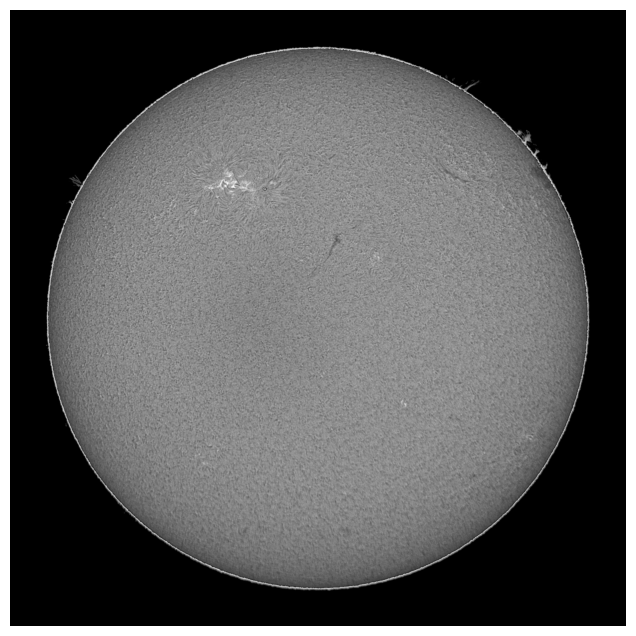

In [14]:
import cv2
import matplotlib.pyplot as plt

image_files = [
    path for path in files
    if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
]

assert image_files, "No supported image files found"

image = cv2.imread(
    str(image_files[0]),
    cv2.IMREAD_UNCHANGED
)

assert image is not None, "Failed to read image"

print("Path:", image_files[0])
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Min pixel:", image.min())
print("Max pixel:", image.max())

plt.figure(figsize=(8, 8))

if image.ndim == 2:
    plt.imshow(image, cmap="gray")
else:
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

plt.axis("off")
plt.show()

In [ ]:
from collections import Counter
import cv2
import pandas as pd

records = []
for path in image_files:
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img is None:
        continue

     records.append({
        "filename": path.name,
        "height": img.shape[0],
        "width": img.shape[1],
        "channels": 1 if img.ndim == 2 else img.shape[2],
        "dtype": str(img.dtype),
        "min": int(img.min()),
        "max": int(img.max()),
    })

df_images = pd.DataFrame(records)

display(df_images.head())
print("Total readable images:", len(df_images))

display(
    df_images.groupby(
        ["height", "width", "channels", "dtype"]
    ).size().reset_index(name="count")
)